---
title: Introduction to Probabilistic Inference
author: Mark Fuge
date: 'October 22 2025'
format:
    html:
        code-fold: true
        code-summary: "Show Code"
---

**Learning Objectives**

By the end of this notebook, you will be able to:

1. Explain why (or under what situations) we would prefer a *distribution* over model parameters rather than a single best fit.
2. Derive the maximum likelihood estimate, the maximum a posteriori (MAP) estimate and the posterior for one unknown quantity measured with known noise, and interpret the differences.
3. Compute and plot the posterior predictive of a Bayesian linear regression, including with nonlinear basis functions, and compare it to ridge regression from the chapter on linear models.
4. Describe the main differences between Markov chain Monte Carlo (MCMC) and variational inference (VI), and name their strengths, weaknesses, and use cases.
5. Use these techniques to give probabilistic/predictive bounds to an example physical model.

Throughout the notebook we'll use a running example of estimating the material properties of a steel test coupon from a supplier, based on measurements you take. The tests will be noisy and there are only a handful of them. We'll use the tools in this notebook to answer how we update our model (or bound its certainty) based on that data.

## Why a Distribution Over Models?

As we saw in prior chapters, when you fit a model to data, you normally get one set of parameters back: the ones that minimize a loss (or a loss and some penalties). In engineering we usually need more than that. We want to know:

- **How uncertain** is the fitted parameter? A yield stress of 235 MPa plus or minus 3 MPa and one of 235 MPa plus or minus 40 MPa lead to very different safety factors.
- **Where** in the input space can we trust the model? A material model fitted on small strains may say nothing reliable about large ones.
- **Would more or better data help?** For example, should we pay for three more specimens or buy a better load cell, and which would be worth the money?

**Bayesian inference** answers all three by keeping a *probability distribution* over parameters instead of a single value. The basic formulation has three ingredients:

- a **prior** $p(\theta)$: what we believe about the parameters before seeing data (e.g., you might imagine getting this from a supplier's datasheet, where they list a nominal value with some spread);
- a **likelihood** $p(\mathcal{D} \mid \theta)$: how probable the observed data are for a given parameter value;
- the **posterior** $p(\theta \mid \mathcal{D}) \propto p(\mathcal{D} \mid \theta)\, p(\theta)$: our updated belief about the parameter value after seeing the data.

Written out in full, this is Bayes' rule:

$$
p(\theta \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \theta)\, p(\theta)}{p(\mathcal{D})},
\qquad
p(\mathcal{D}) = \int p(\mathcal{D} \mid \theta)\, p(\theta)\, d\theta .
$$

The denominator $p(\mathcal{D})$ is called the **evidence**. It is the normalizing constant (i.e., the thing that makes the posterior integrate to 1), and, as we will see, determining it can make inference hard for most types of realistic models we want to fit. The same kind of integral over $\theta$ appears in other things we might want from a posterior:

- **Marginalization**, as in the evidence above: $p(\mathcal{D}) = \int p(\mathcal{D} \mid \theta)\, p(\theta)\, d\theta$.
- **Expectations**, such as the posterior mean of a parameter: $\mathbb{E}[f(\theta)] = \int f(\theta)\, p(\theta \mid \mathcal{D})\, d\theta$.
- **Predictions** for a new measurement $y_*$: $p(y_* \mid \mathcal{D}) = \int p(y_* \mid \theta)\, p(\theta \mid \mathcal{D})\, d\theta$.

Most of this chapter is about computing these integrals.

### The Running Example: A Tensile Test on Mild Steel

Throughout this notebook, we will use a running example of trying to estimate the material properties of steel given test data. Specifically, we will generate synthetic tensile-test data for a mild steel (S235). We will then strain coupons of this material at perscribed strains in a sequence of load steps and measure the corresponding stress for each strain level. In the elastic region stress is proportional to strain through Young's modulus $E$, and beyond the yield stress $\sigma_y$ the material undergoes strain hardening. The Ramberg-Osgood equation captures both regimes with a strain-hardening exponent $n$:

$$
\varepsilon = \frac{\sigma}{E} + \alpha \left(\frac{\sigma}{\sigma_y}\right)^{n}
$$

with $\alpha = 0.002$ (the 0.2 percent offset convention). We will measure the stress at each prescribed strain using a load-cell, however, this load cell has a certain amount of measurement noise (as is the case for any measurement device). We will assume for now that we know the accuracy of this load cell. Since we are generating these stress-strain data points synthetically, using a known set of material parameters, we can check whether we get the correct answer, but our job will be to try to infer these parameters given only the noisy test data that we collect.

In [29]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ipywidgets as widgets
from IPython.display import display

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 0
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# Mild steel S235 (used only to generate data and to check answers)
E_TRUE = 210e3        # Young's modulus [MPa]
SIGMA_Y_TRUE = 235.0  # yield stress [MPa]
ALPHA = 0.002         # Ramberg-Osgood offset constant
N_TRUE = 8.0          # strain-hardening exponent
NOISE_STD = 5.0       # load-cell noise on stress [MPa]


def ramberg_osgood_stress(strain, sigma_y, n, E=E_TRUE, alpha=ALPHA, iterations=15):
    """Stress for a prescribed strain under the Ramberg-Osgood law.

    The law gives strain as a function of stress, so we invert it with a few
    Newton iterations. Broadcasts over all inputs, so it can evaluate many
    parameter values against many strains at once. Works on NumPy arrays and,
    if any argument is a torch tensor, on torch tensors (so gradients can flow).
    """
    if any(torch.is_tensor(a) for a in (strain, sigma_y, n)):
        xp = torch
        strain, sigma_y, n = (torch.as_tensor(a, dtype=torch.float64) for a in (strain, sigma_y, n))
    else:
        xp = np
    # Start from whichever regime dominates: elastic (E * eps) or plastic.
    # Physically meaningless parameters (negative yield stress or exponent) give NaN,
    # which the inference code below treats as "impossible"; silence the warnings.
    with np.errstate(invalid="ignore", over="ignore", divide="ignore"):
        stress = xp.minimum(E * strain, sigma_y * (strain / alpha) ** (1.0 / n))
        for _ in range(iterations):
            ratio = stress / sigma_y
            residual = stress / E + alpha * ratio ** n - strain
            slope = 1.0 / E + alpha * n * ratio ** (n - 1) / sigma_y
            stress = stress - residual / slope
    return stress


def generate_tensile_test(n_points=12, strain_max=1.6e-3, noise_std=NOISE_STD, rng=rng):
    """Synthetic tensile test: n_points prescribed strains, noisy measured stresses (MPa)."""
    strain = np.linspace(strain_max / n_points, strain_max, n_points)
    clean_stress = ramberg_osgood_stress(strain, SIGMA_Y_TRUE, N_TRUE)
    stress = clean_stress + rng.normal(0.0, noise_std, size=n_points)
    return strain, stress


strain_obs, stress_obs = generate_tensile_test()
strain_fine = np.linspace(1e-5, 2.5e-3, 300)
stress_true_curve = ramberg_osgood_stress(strain_fine, SIGMA_Y_TRUE, N_TRUE)

Below is an example plot of the data we collect. You can see that we measure the stress at twelve different strains, and plot over this $2\sigma$ bands of error based on the load cell accuracy.

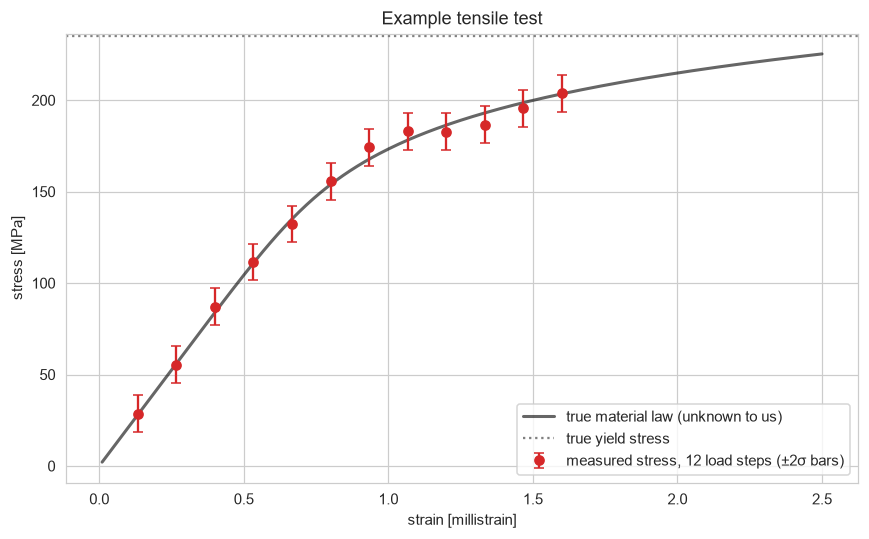

In [61]:
# Plot the tensile test
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(strain_fine * 1e3, stress_true_curve, "k-", lw=2, alpha=0.6, label="true material law (unknown to us)")
ax.errorbar(strain_obs * 1e3, stress_obs, yerr=2 * NOISE_STD, fmt="o", color="C3", ecolor="C3",
            capsize=3, label=f"measured stress, {len(strain_obs)} load steps (±2σ bars)")
ax.axhline(SIGMA_Y_TRUE, color="gray", ls=":", label="true yield stress")
ax.set_xlabel("strain [millistrain]")
ax.set_ylabel("stress [MPa]")
ax.set_title("Example tensile test")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Warm-Up: An unknown Young's Modulus

Let's start with a simple example of just estimating the Young's modulus, given some test data. If we only use small strains, then the material behavior will be close to Hooke's law, $\sigma = E\,\varepsilon$, and the only unknown is Young's modulus $E$. Let's say we run twenty load steps up to half a millistrain on the same specimen. Each measured stress is the true stress plus load-cell noise:

$$
\sigma_i = E\,\varepsilon_i + \epsilon_i, \qquad \epsilon_i \sim \mathcal{N}(0, \sigma_{\text{noise}}^2).
$$

**Prior.** The datasheet from the material supplier says their mild steel has $E \approx 200$ GPa. We encode this as a Gaussian prior $p(E) = \mathcal{N}(\mu_0, \tau_0^2)$ with $\mu_0 = 200$ GPa and a generous $\tau_0 = 20$ GPa, since we are not sure if we trust the supplier's estimate. For a Gaussian, this means we would not be surprised to see moduli as low as 140 GPa ($\mu_0 - 3\tau_0$) or as high as 260 GPa ($\mu_0 + 3\tau_0$).

**Likelihood.** For a candidate $E$, the probability of the measured stresses is a product of Gaussians centered on $E\,\varepsilon_i$. That is, given a bunch ($N$) of stress and strain measurements ($\sigma_i$, $\varepsilon_i$), the total likelihood of those measurements is 

$$
p(\mathcal{D} \mid E) = \prod_{i=1}^N p(\sigma_i \mid E) =  \prod_{i=1}^N \mathcal{N}(\sigma_i;\, E\,\varepsilon_i , \sigma_{\text{noise}}^2).
$$

**Posterior.** Now we multiply the prior and likelihood together, and normalize such that the posterior integrates to 1. Because both the prior and the likelihood are Gaussian in $E$, the product luckily happens to also be Gaussian -- the technical term is that the two distributions are *conjugate* -- and thus its parameters have a closed form:

$$
\frac{1}{\tau_N^2} = \frac{1}{\tau_0^2} + \frac{\sum_i \varepsilon_i^2}{\sigma_{\text{noise}}^2},
\qquad
\mu_N = \tau_N^2 \left( \frac{\mu_0}{\tau_0^2} + \frac{\sum_i \varepsilon_i\,\sigma_i}{\sigma_{\text{noise}}^2} \right).
$$

Precisions (inverse variances) *add*: every measurement makes us more certain. The posterior mean is a precision-weighted average of the prior mean and the estimate of the modulus that corresponds to each test data point: $\sigma_i / \varepsilon_i$.

In [31]:
#| code-fold: false
def gaussian_update(prior_mean, prior_std, strain, stress, noise_std):
    """Posterior over E for Hooke's law with a Gaussian prior and Gaussian noise.

    Returns the posterior mean and standard deviation. Everything is in MPa.
    """
    prior_precision = 1.0 / prior_std**2
    data_precision = np.sum(strain**2) / noise_std**2
    posterior_var = 1.0 / (prior_precision + data_precision)
    posterior_mean = posterior_var * (prior_mean * prior_precision + np.sum(strain * stress) / noise_std**2)
    return posterior_mean, np.sqrt(posterior_var)


# A modulus test stays at small strain, where the response is linear: 20 load steps up to 0.5 millistrain
strain_el, stress_el = generate_tensile_test(n_points=20, strain_max=0.5e-3)

PRIOR_E_MEAN, PRIOR_E_STD = 200e3, 20e3  # MPa
E_post_mean, E_post_std = gaussian_update(PRIOR_E_MEAN, PRIOR_E_STD, strain_el, stress_el, NOISE_STD)
print(f"{len(strain_el)} elastic load steps used")
print(f"Prior:     E = {PRIOR_E_MEAN/1e3:.1f} ± {PRIOR_E_STD/1e3:.1f} GPa")
print(f"Posterior: E = {E_post_mean/1e3:.1f} ± {E_post_std/1e3:.1f} GPa   (true value {E_TRUE/1e3:.0f} GPa)")

20 elastic load steps used
Prior:     E = 200.0 ± 20.0 GPa
Posterior: E = 207.0 ± 3.7 GPa   (true value 210 GPa)


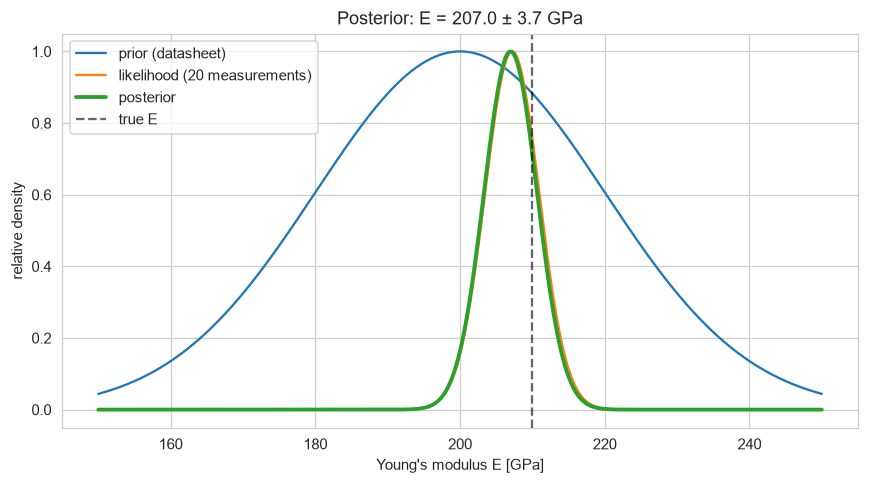

In [32]:
def plot_E_update(prior_mean, prior_std, strain, stress, noise_std, ax=None):
    """Prior, (scaled) likelihood and posterior over E on one axis."""
    post_mean, post_std = gaussian_update(prior_mean, prior_std, strain, stress, noise_std)
    E_grid = np.linspace(150e3, 250e3, 600)
    prior = np.exp(-0.5 * ((E_grid - prior_mean) / prior_std) ** 2)
    log_lik = np.array([-0.5 * np.sum((stress - E * strain) ** 2) / noise_std**2 for E in E_grid])
    likelihood = np.exp(log_lik - log_lik.max())
    posterior = np.exp(-0.5 * ((E_grid - post_mean) / post_std) ** 2)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(E_grid / 1e3, prior / prior.max(), label="prior (datasheet)")
    ax.plot(E_grid / 1e3, likelihood, label=f"likelihood ({len(strain)} measurements)")
    ax.plot(E_grid / 1e3, posterior, lw=2.5, label="posterior")
    ax.axvline(E_TRUE / 1e3, color="k", ls="--", alpha=0.6, label="true E")
    ax.set_xlabel("Young's modulus E [GPa]")
    ax.set_ylabel("relative density")
    ax.set_title(f"Posterior: E = {post_mean/1e3:.1f} ± {post_std/1e3:.1f} GPa")
    ax.legend(loc="upper left")
    return ax


plot_E_update(PRIOR_E_MEAN, PRIOR_E_STD, strain_el, stress_el, NOISE_STD)
plt.tight_layout()
plt.show()

The likelihood is much narrower than the prior, so the posterior essentially follows the data. That is what we hope for: a good experiment should dominate a vague prior. As we will see below, if we only have a single measurement the picture would look different, and the prior would matter.

::: {.callout-tip appearance="default"}
### Experiment: How many load steps do we need?
Before touching the sliders, write down your prediction. What happens to the width of the posterior if you (a) double the number of elastic load steps, and (b) swap in a cheaper load cell with twice the noise? Which of the two changes hurts more? Then use the sliders to check your prediction, and explain the result with the precision formula above.
:::

In [62]:
def experiment_E(n_readings=20, noise_std=5.0, prior_std_GPa=20.0):
    """Regenerate an elastic-only test and show the update."""
    exp_rng = np.random.default_rng(SEED)
    strain = np.linspace(0.5e-3 / n_readings, 0.5e-3, n_readings)
    stress = E_TRUE * strain + exp_rng.normal(0.0, noise_std, size=n_readings)
    plot_E_update(PRIOR_E_MEAN, prior_std_GPa * 1e3, strain, stress, noise_std)
    plt.tight_layout()
    plt.show()


widgets.interact(
    experiment_E,
    n_readings=widgets.IntSlider(value=20, min=1, max=60, description="load steps", continuous_update=False),
    noise_std=widgets.FloatSlider(value=5.0, min=1.0, max=20.0, step=1.0, description="noise [MPa]", continuous_update=False),
    prior_std_GPa=widgets.FloatSlider(value=20.0, min=2.0, max=60.0, step=2.0, description="prior std [GPa]", continuous_update=False),
);

interactive(children=(IntSlider(value=20, continuous_update=False, description='load steps', max=60, min=1), F…

### MLE, MAP and the Full Posterior

We can derive the posterior formula above in three steps. Each step gives a different estimate of $E$.

**Maximum likelihood (MLE).** The log of the likelihood is

$$
\mathrm{LL}(E) = \log p(\mathcal{D} \mid E) = -\frac{N}{2}\log\left(2\pi\sigma_{\text{noise}}^2\right) - \frac{1}{2\sigma_{\text{noise}}^2}\sum_{i=1}^{N} \left(\sigma_i - E\,\varepsilon_i\right)^2 .
$$

Setting its derivative with respect to $E$ to zero gives

$$
\frac{\partial \mathrm{LL}}{\partial E} = \frac{1}{\sigma_{\text{noise}}^2}\sum_{i=1}^{N} \varepsilon_i \left(\sigma_i - E\,\varepsilon_i\right) = 0
\quad\Rightarrow\quad
E_{\text{MLE}} = \frac{\sum_i \varepsilon_i\,\sigma_i}{\sum_i \varepsilon_i^2}.
$$

This is the least-squares fit of a line through the origin. With Gaussian noise, maximizing the log-likelihood is the same as minimizing the squared error. The same recipe works for other models: write out the (log) likelihood, then maximize it, or minimize its negative.

**Maximum a posteriori (MAP).** Now we add the log prior, $\log p(E) = -\frac{(E-\mu_0)^2}{2\tau_0^2} + \text{const}$, and maximize $\log p(\mathcal{D} \mid E) + \log p(E)$. The evidence does not depend on $E$, so we can leave it out:

$$
\frac{\partial}{\partial E}\left[\mathrm{LL}(E) - \frac{(E-\mu_0)^2}{2\tau_0^2}\right] = 0
\quad\Rightarrow\quad
E_{\text{MAP}} = \frac{\mu_0/\tau_0^2 + \sum_i \varepsilon_i\,\sigma_i/\sigma_{\text{noise}}^2}{1/\tau_0^2 + \sum_i \varepsilon_i^2/\sigma_{\text{noise}}^2}.
$$

This is the posterior mean $\mu_N$ from above. For a Gaussian, the peak and the mean are at the same point.

**Full posterior.** The MAP gives only a single number, whereas if we want the whole posterior, we also need to know its width. The log posterior is quadratic in $E$, so the posterior is a Gaussian with mean $E_{\text{MAP}}$. Its second derivative is $-\left(1/\tau_0^2 + \sum_i \varepsilon_i^2/\sigma_{\text{noise}}^2\right) = -1/\tau_N^2$, so a sharper peak means a smaller posterior variance.

The cell below computes the three estimates using only the first few load steps of the warm-up test.

In [34]:
#| code-fold: false
def mle_modulus(strain, stress):
    # Maximum likelihood estimate of E for Hooke's law with Gaussian noise
    return np.sum(strain * stress) / np.sum(strain**2)


for n_steps in [2, 5, 20]:
    strain, stress = strain_el[:n_steps], stress_el[:n_steps]
    E_map, E_std = gaussian_update(PRIOR_E_MEAN, PRIOR_E_STD, strain, stress, NOISE_STD)
    print(f"first {n_steps:2d} load steps (up to {strain.max()*1e3:.3f} millistrain):  "
          f"MLE {mle_modulus(strain, stress)/1e3:6.1f} GPa,  MAP {E_map/1e3:6.1f} GPa,  posterior {E_map/1e3:6.1f} ± {E_std/1e3:4.1f} GPa")

first  2 load steps (up to 0.050 millistrain):  MLE   99.5 GPa,  MAP  195.2 GPa,  posterior  195.2 ± 19.5 GPa
first  5 load steps (up to 0.125 millistrain):  MLE  165.8 GPa,  MAP  187.9 GPa,  posterior  187.9 ± 16.1 GPa
first 20 load steps (up to 0.500 millistrain):  MLE  207.2 GPa,  MAP  207.0 GPa,  posterior  207.0 ±  3.7 GPa


With only the first two load steps, the stresses are about 5 and 10 MPa and the noise is 5 MPa. The MLE uses only these two readings and gives about 100 GPa, far below the modulus of any steel. The MAP estimate stays close to the datasheet value of 200 GPa, and the posterior standard deviation is still about 20 GPa. With all 20 load steps, the three estimates agree. The prior matters most when there are few data or the data are noisy.

## Bayesian Linear Regression

The above example was only for a single parameter -- Young's modulus $E$. We'll now start looking at what happens when we add more parameters and more complex models.

Let's start by assuming that the load cell we are using has a small offset at zero load (say, grip settling, a pre-load, etc.) and so we might not see exactly zero stress at zero strain. A more honest elastic model would have two unknowns, an offset $w_0$ and the modulus $w_1 = E$:

$$
\sigma_i = w_0 + w_1\,\varepsilon_i + \epsilon_i = \mathbf{w}^\top \mathbf{x}_i + \epsilon_i,
\qquad \mathbf{x}_i = \begin{bmatrix} 1 \\ \varepsilon_i \end{bmatrix},
\qquad \epsilon_i \sim \mathcal{N}(0, \sigma_{\text{noise}}^2).
$$

Here $\mathbf{x}_i$ is the feature vector of measurement $i$. One measurement has the likelihood $p(\sigma_i \mid \mathbf{x}_i, \mathbf{w}) = \mathcal{N}(\sigma_i;\, \mathbf{w}^\top \mathbf{x}_i,\, \sigma_{\text{noise}}^2)$, and for independent measurements the likelihood of all of them is the product over $i$.

We put a Gaussian prior on the weights, $p(\mathbf{w}) = \mathcal{N}(\mathbf{0}, \tau^2 \mathbf{I})$, where $\tau$ is the prior standard deviation of each weight. We center this prior on zero and make it very wide, so that we can compare the result with ridge regression below. So, unlike in the warm-up, we do not use the 200 GPa datasheet value here. The prior also pulls the offset $w_0$ slightly toward zero. The posterior over the weight vector is again Gaussian, now in two dimensions:

$$
p(\mathbf{w} \mid \mathcal{D}) = \mathcal{N}(\mathbf{m}_N, \mathbf{S}_N), \qquad
\mathbf{S}_N = \left(\frac{1}{\tau^2}\,\mathbf{I} + \frac{1}{\sigma_{\text{noise}}^2}\,\mathbf{X}^\top\mathbf{X}\right)^{-1}, \qquad
\mathbf{m}_N = \frac{1}{\sigma_{\text{noise}}^2}\,\mathbf{S}_N\,\mathbf{X}^\top \boldsymbol{\sigma}.
$$

Each row of the matrix $\mathbf{X}$ is one feature vector $\mathbf{x}_i^\top$, and the vector $\boldsymbol{\sigma}$ contains the measured stresses. $\mathbf{S}_N$ is the posterior covariance of the weights. With a single weight and $\mathbf{x}_i = \varepsilon_i$, $\mathbf{S}_N$ has the same form as the warm-up's $\tau_N^2$. The mean is different, because the prior mean is now zero. This model is called **Bayesian linear regression**.

### The Posterior Predictive

Engineers usually care less about $\mathbf{w}$ than about the stress at a strain they have *not* tested. Call the feature vector of that strain $\mathbf{x}_*$. The **posterior predictive** averages the model's prediction over all weight vectors, weighted by their posterior probability:

$$
p(\sigma_* \mid \mathbf{x}_*, \mathcal{D}) = \int p(\sigma_* \mid \mathbf{x}_*, \mathbf{w})\, p(\mathbf{w} \mid \mathcal{D})\, d\mathbf{w}
= \mathcal{N}\!\left(\mathbf{m}_N^\top \mathbf{x}_*,\; \sigma_{\text{noise}}^2 + \mathbf{x}_*^\top \mathbf{S}_N\, \mathbf{x}_*\right).
$$

The predictive variance has two parts: the measurement noise, which does not shrink with more data, and a term that grows as $\varepsilon_*$ moves away from the strains we measured.


In [35]:
#| code-fold: false
class BayesianLinearRegression:
    """Bayesian linear regression with a Gaussian prior N(0, prior_std^2 I) and Gaussian noise.

    The model is linear in the weights, but the features may be any functions
    of the strain; polynomial features of a chosen degree are built in.
    """

    def __init__(self, degree=1, prior_std=1000.0, noise_std=1.0, scale=1.0):
        """
        Args:
            degree: polynomial degree of the features (1 = offset + slope)
            prior_std: tau, the prior standard deviation of each weight (large = weak prior)
            noise_std: sigma_noise, the measurement noise standard deviation
            scale: divides the strain before building features so powers stay well conditioned
        """
        self.degree = degree
        self.prior_std = prior_std
        self.noise_std = noise_std
        self.scale = scale
        self.m_N = None
        self.S_N = None

    def features(self, strain):
        """Matrix X whose row i is the feature vector x_i = [1, eps_i, eps_i^2, ..., eps_i^degree] (strain rescaled)."""
        eps = np.asarray(strain, dtype=float).reshape(-1, 1) / self.scale
        return np.concatenate([eps**k for k in range(self.degree + 1)], axis=1)

    def fit(self, strain, stress):
        """Closed-form posterior over the weights."""
        X = self.features(strain)
        n_weights = X.shape[1]
        self.S_N = np.linalg.inv(np.eye(n_weights) / self.prior_std**2 + X.T @ X / self.noise_std**2)
        self.m_N = self.S_N @ X.T @ stress / self.noise_std**2
        return self

    def predict(self, strain_new):
        """Posterior predictive mean and standard deviation at new strains."""
        X = self.features(strain_new)
        mean = X @ self.m_N
        var = self.noise_std**2 + np.sum(X @ self.S_N * X, axis=1)
        return mean, np.sqrt(var)

    def sample_functions(self, strain_new, n_samples=20, rng=rng):
        """Draw weight vectors from the posterior and evaluate the corresponding curves."""
        w = rng.multivariate_normal(self.m_N, self.S_N, size=n_samples)
        return self.features(strain_new) @ w.T


blr_elastic = BayesianLinearRegression(degree=1, noise_std=NOISE_STD, scale=1e-3)
blr_elastic.fit(strain_el, stress_el)
offset, modulus = blr_elastic.m_N
# With strain rescaled to millistrain, the slope weight is numerically Young's modulus in GPa.
print(f"posterior mean: offset w0 = {offset:.1f} MPa,  modulus w1 = {modulus:.1f} GPa (true {E_TRUE/1e3:.0f} GPa)")
print(f"posterior std:  offset    = {np.sqrt(blr_elastic.S_N[0, 0]):.1f} MPa,  modulus    = {np.sqrt(blr_elastic.S_N[1, 1]):.1f} GPa")

posterior mean: offset w0 = -2.8 MPa,  modulus w1 = 215.3 GPa (true 210 GPa)
posterior std:  offset    = 2.3 MPa,  modulus    = 7.8 GPa


### Connection to Ridge Regression

Take the log of the posterior and drop the terms that do not depend on $\mathbf{w}$:

$$
\log p(\mathbf{w} \mid \mathcal{D}) = -\frac{1}{2\sigma_{\text{noise}}^2} \sum_{i=1}^{N} \left(\sigma_i - \mathbf{w}^\top \mathbf{x}_i\right)^2 - \frac{1}{2\tau^2}\,\lVert \mathbf{w} \rVert^2 + \text{const}.
$$

Multiplying by $-2\sigma_{\text{noise}}^2$ shows that maximizing the log posterior is the same as minimizing

$$
\sum_{i=1}^{N} \left(\sigma_i - \mathbf{w}^\top \mathbf{x}_i\right)^2 + \lambda \lVert \mathbf{w} \rVert^2, \qquad \lambda = \frac{\sigma_{\text{noise}}^2}{\tau^2}.
$$

This is ridge regression, the $L_2$ penalty from the chapter on linear models. The squared error comes from the likelihood, and the penalty comes from the prior. Setting the gradient with respect to $\mathbf{w}$ to zero gives

$$
\left(\mathbf{X}^\top\mathbf{X} + \lambda\,\mathbf{I}\right)\mathbf{w} = \mathbf{X}^\top\boldsymbol{\sigma}
\quad\Rightarrow\quad
\mathbf{w}_{\text{MAP}} = \left(\mathbf{X}^\top\mathbf{X} + \lambda\,\mathbf{I}\right)^{-1}\mathbf{X}^\top\boldsymbol{\sigma}.
$$

Since $\mathbf{S}_N = \sigma_{\text{noise}}^2\left(\mathbf{X}^\top\mathbf{X} + \lambda\,\mathbf{I}\right)^{-1}$, this is $\mathbf{m}_N$. So the ridge solution is the MAP estimate, and here also the posterior mean. The penalty weight $\lambda$ is the noise variance divided by the prior variance of the weights, so a wide prior gives a small penalty. Our prior is very wide ($\tau = 1000$, in MPa for the offset and in GPa for the modulus), so $\lambda$ is close to zero and $\mathbf{m}_N$ is close to the ordinary least-squares fit.

Ridge regression gives only the weight vector. Bayesian linear regression also gives $\mathbf{S}_N$, which tells us how far the weights can change and still fit the data. The band in the next plot is computed from $\mathbf{S}_N$.

Let's first plot the estimate of the linear model in the elastic regime:

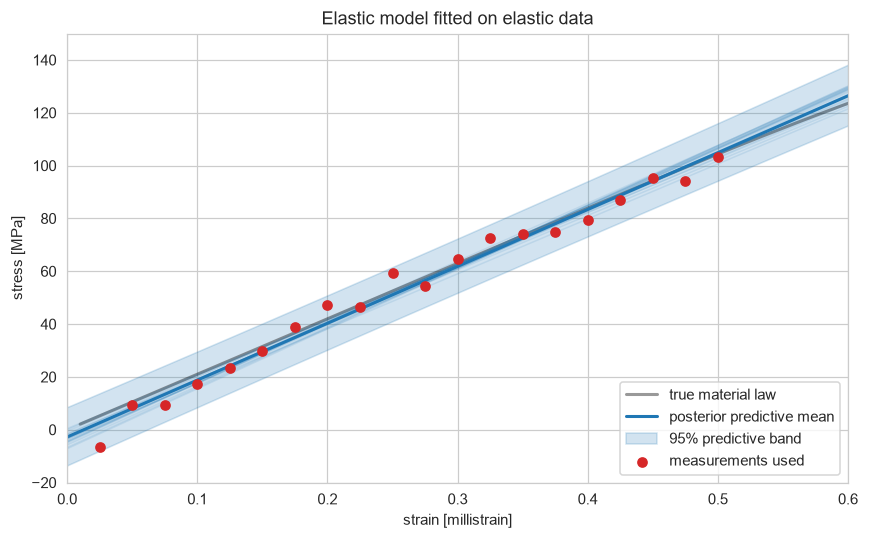

In [ ]:
def plot_predictive(model, strain, stress, strain_plot, title, ax=None, n_curves=20):
    """Data, posterior predictive mean, 95 percent band, and a few posterior curves."""
    mean, std = model.predict(strain_plot)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
    ax.plot(strain_fine * 1e3, stress_true_curve, "k-", lw=2, alpha=0.4, label="true material law")
    for curve in model.sample_functions(strain_plot, n_curves).T:
        ax.plot(strain_plot * 1e3, curve, color="C0", alpha=0.12, lw=1)
    ax.plot(strain_plot * 1e3, mean, color="C0", lw=2, label="posterior predictive mean")
    ax.fill_between(strain_plot * 1e3, mean - 2 * std, mean + 2 * std, color="C0", alpha=0.2, label="95% predictive band")
    ax.scatter(strain * 1e3, stress, color="C3", zorder=5, label="measurements used")
    ax.set_xlabel("strain [millistrain]")
    ax.set_ylabel("stress [MPa]")
    ax.set_title(title)
    ax.set_ylim(-20, 320)
    ax.legend(loc="lower right")
    return ax


strain_plot = np.linspace(0, 2.0e-3, 200)
ax = plot_predictive(blr_elastic, strain_el, stress_el, strain_plot, "Elastic model fitted on elastic data")
# Limit the x-axis and y-axis to the elastic regime for clarity
ax.set_xlim(0, 0.6)
ax.set_ylim(-20, 150)
plt.tight_layout()
plt.show()

So far so good! we can see that it roughly matches the apppropriate modulus and that the sampled slopes (the thin blue lines) and the predictive band are capturing possible slopes and likely measurements, respectively. 

But how this this compare if we look over the entire range?

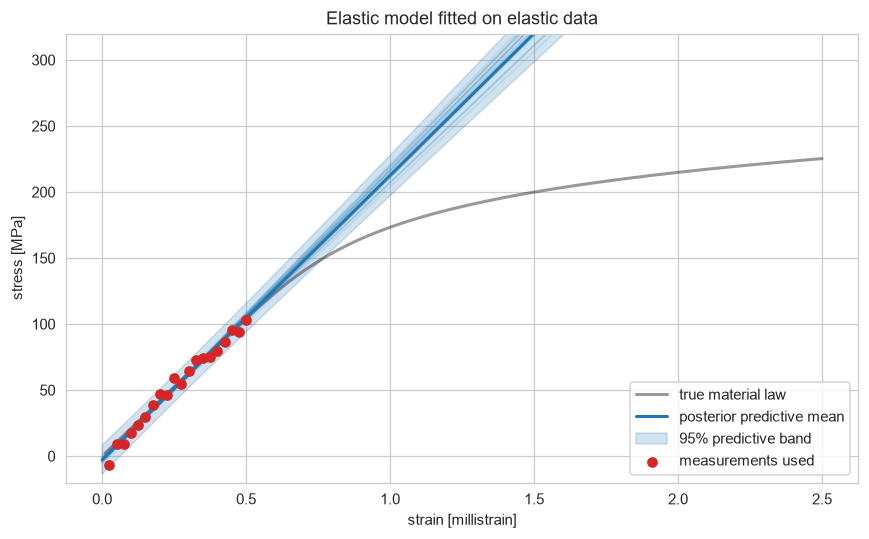

In [ ]:
plot_predictive(blr_elastic, strain_el, stress_el, strain_plot, "Elastic model fitted on elastic data")
plt.tight_layout()
plt.show()

Past the last measurement, we see that the band widens slowly because the slope is uncertain.

When the material yields, the straight line keeps rising and no longer matches the true curve. The band describes the uncertainty in the parameters of the straight-line model, but it doesn't tell us whether our straight-line model itself is right!

## "Non-Linear" Linear Regression

As we saw in earlier chapters, Linear regression can fit curves, because *linear* refers to the parameters, not to the input. If we replace the feature vector $\mathbf{x}_i = [1, \varepsilon_i]^\top$ with $[1, \varepsilon_i, \varepsilon_i^2, \dots, \varepsilon_i^d]^\top$, the model can bend, and the posterior formulas above stay the same, because the stress is still a weighted sum of fixed functions of strain. Here it gives an exact posterior for a curved fit.

Let's fit the full elastic-plastic curve with polynomial features.

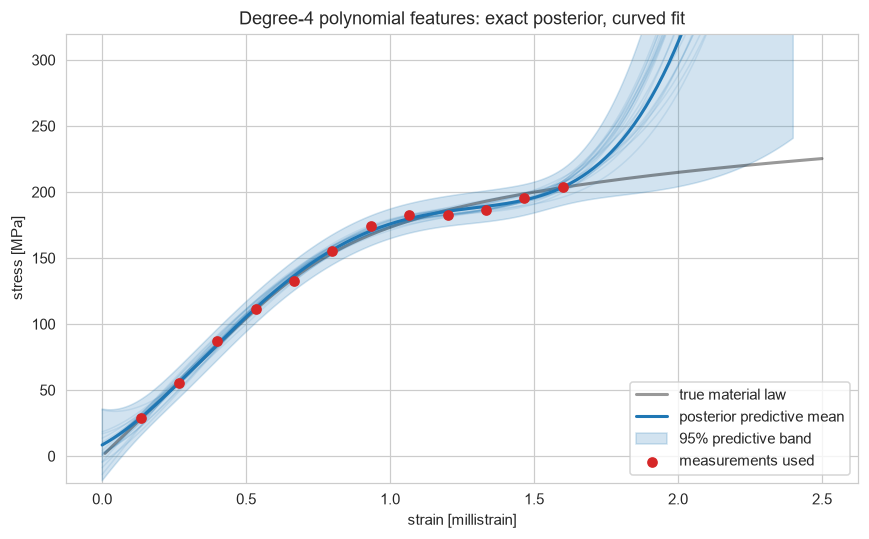

In [37]:
blr_poly = BayesianLinearRegression(degree=4, noise_std=NOISE_STD, scale=1e-3)
blr_poly.fit(strain_obs, stress_obs)
strain_extrap = np.linspace(0, 2.4e-3, 240)
plot_predictive(blr_poly, strain_obs, stress_obs, strain_extrap, "Degree-4 polynomial features: exact posterior, curved fit")
plt.tight_layout()
plt.show()

The fit follows the knee of the curve, and the band is narrow where we have measurements. However, beyond the last load step the band grows quickly, because our proposed polynomial model extrapolates poorly in this case. The polynomial also contains no physics: nothing in the model says that the stress should keep increasing with strain. So outside the data, the band describes uncertainty about polynomial curves, not about the material.

::: {.callout-tip appearance="default"}
### Experiment: Degree and data density
If you raise the polynomial degree from 2 to 8 with the same 12 points, does the band inside the data get narrower or wider? What if you keep degree 4 but use only the first six load steps (say the extensometer slipped)? Use the sliders and explain what you see in terms of how many parameters the data must pin down.
:::

In [38]:
def experiment_poly(degree=4, n_points_kept=12):
    """Refit the polynomial model on the first n_points_kept load steps."""
    model = BayesianLinearRegression(degree=degree, noise_std=NOISE_STD, scale=1e-3)
    model.fit(strain_obs[:n_points_kept], stress_obs[:n_points_kept])
    plot_predictive(model, strain_obs[:n_points_kept], stress_obs[:n_points_kept], strain_extrap,
                    f"degree {degree}, {n_points_kept} load steps")
    plt.tight_layout()
    plt.show()


widgets.interact(
    experiment_poly,
    degree=widgets.IntSlider(value=4, min=1, max=9, description="degree", continuous_update=False),
    n_points_kept=widgets.IntSlider(value=12, min=3, max=12, description="load steps", continuous_update=False),
);

interactive(children=(IntSlider(value=4, continuous_update=False, description='degree', max=9, min=1), IntSlid…

## What about truely non-linear models?

The polynomial weights have no physical meaning. What we want are the parameters of the material law: the yield stress $\sigma_y$ and the hardening exponent $n$. So we can instead put the Ramberg-Osgood law itself into the likelihood. To keep the problem two-dimensional, so that we can plot it, we fix $E$ at the posterior mean from the warm-up and treat $\sigma_y$ and $n$ as the two unknowns:

$$
\sigma_i = \sigma_{\text{RO}}(\varepsilon_i;\, \sigma_y, n) + \epsilon_i .
$$

Unfortunately, now we have no closed-form posterior! The function $\sigma_{\text{RO}}$ is not a weighted sum of fixed features: $\sigma_y$ and $n$ appear inside a power law, and we even solve a nonlinear equation to evaluate it. A Gaussian likelihood times a Gaussian prior is then no longer a Gaussian in $(\sigma_y, n)$. There is no formula for the posterior mean, for its width, or for the normalizing constant. Such a posterior is called **intractable**. We can evaluate $p(\mathcal{D} \mid \theta)\,p(\theta)$ at any $\theta$, but we cannot integrate it in closed form.

To make things simple in this chapter we fixed $E$ at a point estimate, but this ignores the uncertainty in $E$ that we computed above, and an error in $E$ will of course shift the estimates of the other two parameters. We will cover this more complex case in the probabilistic programming chapter, where we will infer all three parameters together. However, for now we will fix $E$ so that we can actually plot the posterior.

For the priors we again use loose datasheet values: $\sigma_y \sim \mathcal{N}(250, 50^2)$ MPa and $n \sim \mathcal{N}(8, 4^2)$.

In [39]:
#| code-fold: false
E_FIXED = E_post_mean  # from the warm-up
PRIOR_SY = (250.0, 50.0)  # mean, std [MPa]
PRIOR_N = (8.0, 4.0)

def log_prior(sigma_y, n):
    """Log of the Gaussian priors (up to a constant). Broadcasts over parameter arrays."""
    return -0.5 * ((sigma_y - PRIOR_SY[0]) / PRIOR_SY[1]) ** 2 - 0.5 * ((n - PRIOR_N[0]) / PRIOR_N[1]) ** 2


def log_likelihood(sigma_y, n, strain=strain_obs, stress=stress_obs, noise_std=NOISE_STD):
    """Log-likelihood of the measured stresses for parameter values sigma_y, n (any broadcastable shape)."""
    predicted = ramberg_osgood_stress(strain, sigma_y[..., None], n[..., None], E=E_FIXED)
    if torch.is_tensor(predicted):  # keep data and prediction in the same library
        stress = torch.as_tensor(stress, dtype=torch.float64)
    return -0.5 * ((stress - predicted) ** 2).sum(-1) / noise_std**2


def log_posterior(sigma_y, n, **kwargs):
    """Unnormalized log posterior: log likelihood + log prior."""
    return log_likelihood(sigma_y, n, **kwargs) + log_prior(sigma_y, n)

## Computing the Posterior on a Grid

Having an intractable posterior means that there is no closed form eqeuation for it, but we can compute the numerical value of the posterior at different settings of $\sigma_y$ and $n$. If we only have two unknowns, then we can use brute force: we can evaluate the unnormalized posterior on a fine grid over $(\sigma_y, n)$ and then divide by the sum, so that the values add up to one. For our purposes this is the exact posterior, and we'll use it below to compare every approximation with the "true answer."

While this will work for this notebook, unfortunately, this approach does not scale. A grid of about 140 by 140 points needs about 20,000 evaluations, and each evaluation solves the material law at all 12 load steps. That takes about half a second on a laptop. Each extra parameter at the same resolution multiplies the cost by 140, so ten parameters would need about $140^{10} \approx 3 \times 10^{21}$ evaluations. A neural network has thousands of parameters, so a grid is only an option for very small problems.

If we cannot brute force the posterior calculations, then what are our other options? There are three broad ways to compute a posterior:

1. **Analytically**, by hand. This only works for special pairs of prior and likelihood, called *conjugate* priors, such as the Gaussian prior and Gaussian likelihood of the warm-up and of Bayesian linear regression. We used this approach above.
2. **Exact inference algorithms** for models with special structure, such as the Kalman filter for linear dynamic systems, or message passing on graphs. These are interesting and very practical, but we do not cover these here, since they require special problem structures and thus aren't very general.
3. **Approximate inference**: numerical integration on a grid (quadrature), which only works for a few parameters, as we just saw; **sampling** methods such as MCMC; and **variational** methods (VI). The rest of this chapter covers the last two.

In [40]:
#| code-fold: false
sy_grid = np.linspace(170.0, 310.0, 141)
n_grid = np.linspace(2.0, 20.0, 145)
SY, NN = np.meshgrid(sy_grid, n_grid, indexing="ij")

log_post_grid = log_posterior(SY, NN)
posterior_grid = np.exp(log_post_grid - log_post_grid.max())
posterior_grid = posterior_grid / posterior_grid.sum()   # normalize: the grid values sum to one

# Moments of the true posterior, for reference later
grid_mean_sy = np.sum(SY * posterior_grid)
grid_mean_n = np.sum(NN * posterior_grid)
grid_std_sy = np.sqrt(np.sum((SY - grid_mean_sy) ** 2 * posterior_grid))
grid_std_n = np.sqrt(np.sum((NN - grid_mean_n) ** 2 * posterior_grid))
grid_corr = np.sum((SY - grid_mean_sy) * (NN - grid_mean_n) * posterior_grid) / (grid_std_sy * grid_std_n)
print(f"true posterior:  sigma_y = {grid_mean_sy:.1f} ± {grid_std_sy:.1f} MPa,  n = {grid_mean_n:.2f} ± {grid_std_n:.2f},  correlation {grid_corr:.2f}")
print(f"true values:     sigma_y = {SIGMA_Y_TRUE:.1f} MPa,  n = {N_TRUE:.1f}")

true posterior:  sigma_y = 224.3 ± 7.7 MPa,  n = 10.63 ± 2.01,  correlation -0.88
true values:     sigma_y = 235.0 MPa,  n = 8.0


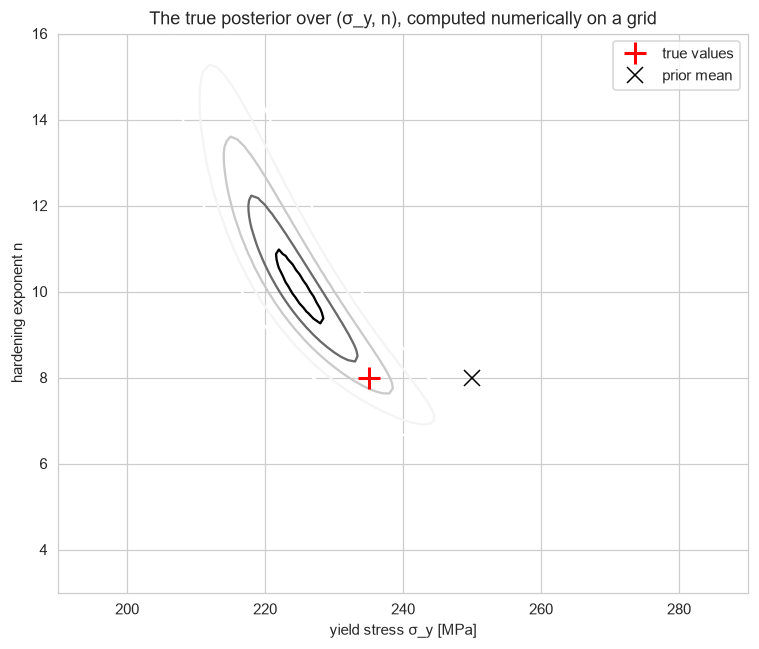

In [74]:
def contour_levels(p):
    """Contour levels at fixed fractions of the peak so plots stay comparable."""
    return np.array([0.02, 0.1, 0.3, 0.6, 0.9]) * p.max()


def plot_true_posterior(ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ax.plot(SIGMA_Y_TRUE, N_TRUE, "r+", ms=14, mew=2, label="true values")
    ax.plot(PRIOR_SY[0], PRIOR_N[0], "kx", ms=10, label="prior mean")
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_ylabel("hardening exponent n")
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 16)
    return ax


ax = plot_true_posterior()
ax.set_title("The true posterior over (σ_y, n), computed numerically on a grid")
ax.legend()
plt.tight_layout()
plt.show()

The posterior is a curved, tilted ridge, not an ellipse. The tilt shows that the two parameters are correlated: a slightly higher yield stress together with a slightly lower hardening exponent gives almost the same curve over the strains we tested. The ridge is also curved, so this relation is not linear. Twelve noisy points at small strain do not determine the knee of the curve well. The true values (red cross) lie inside the ridge, toward its lower-right end, but not at its peak. With this little data, and with $E$ fixed at an estimate, this is expected.

The methods below try to reproduce this posterior without evaluating it on a grid.

## Integrals From Samples

Every quantity in the list at the start of the chapter is an integral over $\theta$. If we can draw samples $\theta_1, \dots, \theta_S$ from the posterior, we can replace each integral by an average:

$$
\mathbb{E}_{p(\theta \mid \mathcal{D})}\left[f(\theta)\right] = \int f(\theta)\, p(\theta \mid \mathcal{D})\, d\theta \approx \frac{1}{S}\sum_{s=1}^{S} f(\theta_s).
$$

This is the **Monte Carlo** approximation. With $f(\theta) = \theta$ it gives the posterior mean. With $f$ the predicted stress at some strain, it gives the predictive band at the end of this chapter. For independent samples, its error shrinks like $1/\sqrt{S}$, independent of the number of parameters.

But we cannot sample the posterior directly. Instead, we can sample from a distribution $q(\theta)$ that is easy to sample, and correct for the difference with weights. Multiplying and dividing by $q$ gives

$$
\mathbb{E}_{p(\theta \mid \mathcal{D})}\left[f(\theta)\right] = \int f(\theta)\, \frac{p(\theta \mid \mathcal{D})}{q(\theta)}\, q(\theta)\, d\theta
\approx \frac{\sum_s \omega_s\, f(\theta_s)}{\sum_s \omega_s},
\qquad \theta_s \sim q, \quad \omega_s = \frac{p(\mathcal{D} \mid \theta_s)\, p(\theta_s)}{q(\theta_s)} .
$$

This is **importance sampling**. The evidence appears in both the numerator and the denominator, so it cancels. The simplest choice is $q(\theta) = p(\theta)$; then each weight equals the likelihood of its sample. The cell below tries this with 10 000 prior samples and computes the *effective sample size* $S_{\text{eff}} = \left(\sum_s \omega_s\right)^2 / \sum_s \omega_s^2$. It equals $S$ when all weights are equal and 1 when a single sample has all the weight.

effective sample size: 388 of 10000 prior samples (3.9 percent)
importance-sampling estimate: sigma_y = 224.1 MPa,  n = 10.68
grid (true posterior):        sigma_y = 224.3 MPa,  n = 10.63


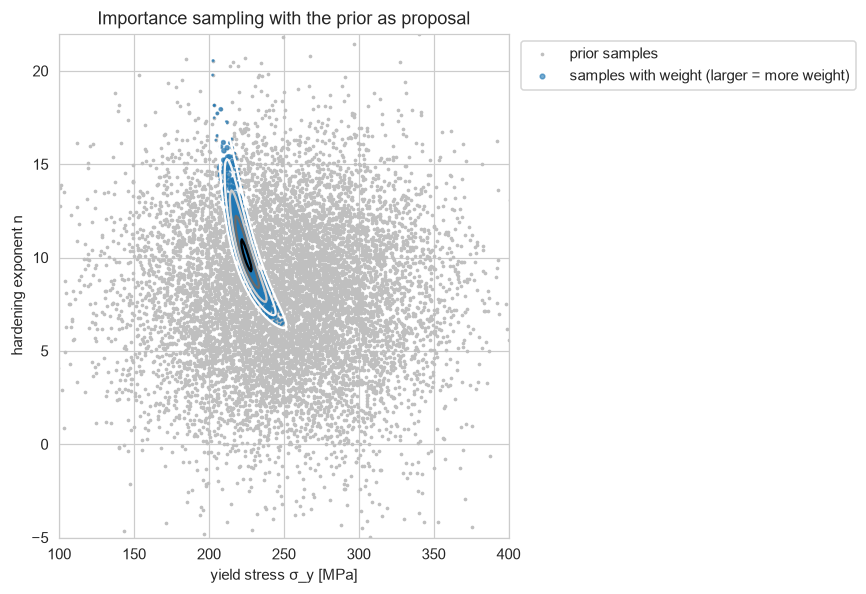

In [42]:
IS_SAMPLES = 10_000
is_rng = np.random.default_rng(SEED)
theta_prior = np.stack([is_rng.normal(PRIOR_SY[0], PRIOR_SY[1], IS_SAMPLES),
                        is_rng.normal(PRIOR_N[0], PRIOR_N[1], IS_SAMPLES)], axis=1)
log_w = log_likelihood(theta_prior[:, 0], theta_prior[:, 1])   # q = prior, so the weight is the likelihood
log_w = np.where(np.isfinite(log_w), log_w, -np.inf)            # impossible parameters (n < 0) get weight zero
is_weights = np.exp(log_w - log_w.max())
is_weights = is_weights / is_weights.sum()
ess = 1.0 / np.sum(is_weights**2)
print(f"effective sample size: {ess:.0f} of {IS_SAMPLES} prior samples ({100 * ess / IS_SAMPLES:.1f} percent)")
print(f"importance-sampling estimate: sigma_y = {np.sum(is_weights * theta_prior[:, 0]):.1f} MPa,  n = {np.sum(is_weights * theta_prior[:, 1]):.2f}")
print(f"grid (true posterior):        sigma_y = {grid_mean_sy:.1f} MPa,  n = {grid_mean_n:.2f}")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(theta_prior[:, 0], theta_prior[:, 1], s=2, color="0.75", label="prior samples")
heavy = is_weights > 1e-4
ax.scatter(theta_prior[heavy, 0], theta_prior[heavy, 1], s=4000 * is_weights[heavy], color="C0", alpha=0.6,
           label="samples with weight (larger = more weight)")
ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
ax.set_xlim(100, 400)
ax.set_ylim(-5, 22)
ax.set_xlabel("yield stress σ_y [MPa]")
ax.set_ylabel("hardening exponent n")
ax.set_title("Importance sampling with the prior as proposal")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

The effective sample size is about 4 percent of the number of samples, because most prior samples fall where the likelihood is tiny. The weighted means are still close to the grid values, because the problem has only two parameters. With more parameters, the region of high posterior probability is a much smaller part of the prior, and almost all the weight falls on a few samples. MCMC avoids this problem: it proposes each new sample near the previous one, so the samples stay in the region of high posterior probability.

## Two Ways to Approximate the Posterior

Both methods only need to evaluate the unnormalized log posterior at a point.

**Markov chain Monte Carlo (MCMC).** We take a random walk through parameter space. The version below is the Metropolis-Hastings algorithm, the simplest member of the family:

1. Start at some point $\theta_0$ (here the prior mean).
2. Propose a random step from the current point: $\theta^* = \theta_t + \boldsymbol{\delta} \odot \boldsymbol{\xi}$, with $\boldsymbol{\xi} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and a step size $\delta_j$ for each parameter.
3. Accept the proposal with probability $a$ (below). If it is accepted, $\theta_{t+1} = \theta^*$. Otherwise the chain stays at the same point, $\theta_{t+1} = \theta_t$.
4. Repeat from step 2.

The acceptance probability is

$$
a = \min\left(1,\; \frac{p(\mathcal{D} \mid \theta^*)\, p(\theta^*)}{p(\mathcal{D} \mid \theta_t)\, p(\theta_t)}\right).
$$

The evidence $p(\mathcal{D})$ appears in both the numerator and the denominator of the ratio, so it cancels, and we only need the unnormalized posterior. (In general the ratio also contains the proposal densities, which is the *Hastings* part of the name. Our Gaussian proposal is symmetric, so these cancel as well.) A step to a point with a higher posterior is always accepted. A step to a point with a lower posterior is accepted with a probability equal to the ratio of the two posterior values. After many steps, the fraction of steps the chain spends in a region equals the posterior probability of that region. The sequence $\theta_0, \theta_1, \dots$ is called the **trace** of the chain. After an initial phase (see below), its points are samples from the posterior, and we can use them in the Monte Carlo average above.

**Variational inference (VI)** works differently: it turns the integration problem into an optimization problem. We derive it below, just before its code.

We run both methods below, look at how each one works, and then compare their results with the grid posterior.

In [43]:
#| code-fold: false
def metropolis_hastings(log_target, start, step_scale, n_steps=20000, burn_in=2000, seed=SEED):
    """Random-walk Metropolis-Hastings sampler for a 2D target.

    Args:
        log_target: function (sigma_y, n) -> unnormalized log posterior
        start: starting point [sigma_y, n]
        step_scale: proposal standard deviation for each parameter
        n_steps: total steps; the first burn_in are discarded
    Returns:
        samples (n_steps - burn_in, 2) and the acceptance rate
    """
    gen = np.random.default_rng(seed)
    current = np.array(start, dtype=float)
    current_logp = log_target(current[0], current[1])
    step_scale = np.asarray(step_scale, dtype=float)
    samples = np.empty((n_steps, 2))
    accepted = 0
    for i in range(n_steps):
        proposal = current + step_scale * gen.standard_normal(2)
        proposal_logp = log_target(proposal[0], proposal[1])
        # Accept with probability min(1, p(proposal) / p(current))
        if np.log(gen.uniform()) < proposal_logp - current_logp:
            current, current_logp = proposal, proposal_logp
            accepted += 1
        samples[i] = current
    return samples[burn_in:], accepted / n_steps


MH_STEP = [6.0, 1.0]  # proposal standard deviations for sigma_y [MPa] and n
mh_samples, mh_acceptance = metropolis_hastings(log_posterior, start=[PRIOR_SY[0], PRIOR_N[0]], step_scale=MH_STEP)
print(f"MCMC: {len(mh_samples)} samples kept, acceptance rate {mh_acceptance:.2f}")
print(f"MCMC: sigma_y = {mh_samples[:, 0].mean():.1f} ± {mh_samples[:, 0].std():.1f} MPa,  n = {mh_samples[:, 1].mean():.2f} ± {mh_samples[:, 1].std():.2f}")

MCMC: 18000 samples kept, acceptance rate 0.41
MCMC: sigma_y = 224.5 ± 7.4 MPa,  n = 10.55 ± 1.95


### How MCMC samples points

The chain starts at the prior mean (black square), outside the ridge. The figure below shows its path after 10, 100, 1000 and 2000 steps, on top of the grid posterior. Each line segment is an accepted step. When a proposal is rejected, the chain stays at the same point, so there are fewer distinct points than steps.

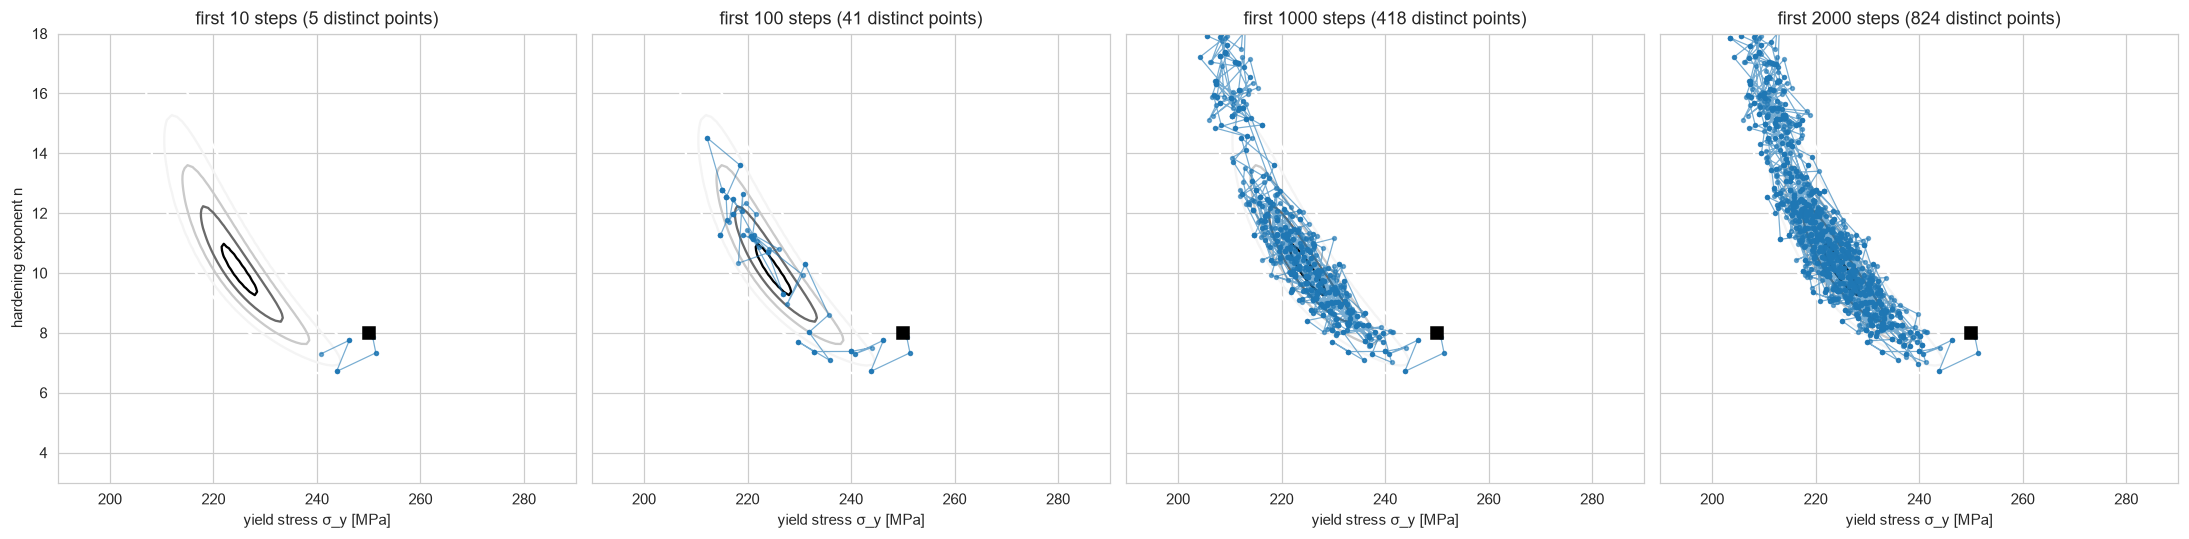

In [44]:
MCMC_SNAPSHOTS = [10, 100, 1000, 2000]   # steps to show
mh_chain, _ = metropolis_hastings(log_posterior, start=[PRIOR_SY[0], PRIOR_N[0]], step_scale=MH_STEP,
                                  n_steps=max(MCMC_SNAPSHOTS), burn_in=0)   # same seed: the first steps of the chain above

fig, axes = plt.subplots(1, len(MCMC_SNAPSHOTS), figsize=(5 * len(MCMC_SNAPSHOTS), 5), sharex=True, sharey=True)
for ax, k in zip(axes, MCMC_SNAPSHOTS):
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ax.plot(mh_chain[:k, 0], mh_chain[:k, 1], "-o", ms=2.5, lw=0.8, color="C0", alpha=0.6)
    ax.plot(PRIOR_SY[0], PRIOR_N[0], "ks", ms=8)
    ax.set_title(f"first {k} steps ({len(np.unique(mh_chain[:k], axis=0))} distinct points)")
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 18)
axes[0].set_ylabel("hardening exponent n")
plt.tight_layout()
plt.show()

The chain reaches the ridge within a few dozen steps and then moves along it. The first steps, before it reaches the ridge, are not samples from the posterior. This is why `metropolis_hastings` discards the first steps as *burn-in*. We discard 2000 steps to be safe.

The slider below steps through the same stored chain. You can move it forward and backward, or press play. The left panel shows the path so far, with the last 50 steps darker and the current point in red. The right panels are *trace plots*: each parameter against the step number. A flat stretch in a trace plot means that the proposals there were rejected.

In [45]:
def show_chain_step(step=10):
    # Path of the stored chain mh_chain up to `step`, and its trace plots
    fig = plt.figure(figsize=(14, 5))
    grid_spec = fig.add_gridspec(2, 2, width_ratios=[1, 1.3])
    ax = fig.add_subplot(grid_spec[:, 0])
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ax.plot(mh_chain[:step, 0], mh_chain[:step, 1], "-", lw=0.6, color="C0", alpha=0.25)
    recent = mh_chain[max(0, step - 50):step]
    ax.plot(recent[:, 0], recent[:, 1], "-o", ms=3, lw=1.0, color="C0", alpha=0.9)
    ax.plot(PRIOR_SY[0], PRIOR_N[0], "ks", ms=8)
    ax.plot(mh_chain[step - 1, 0], mh_chain[step - 1, 1], "o", color="C3", ms=9)
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 18)
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_ylabel("hardening exponent n")
    ax.set_title(f"step {step}: {len(np.unique(mh_chain[:step], axis=0))} distinct points so far")

    steps = np.arange(1, step + 1)
    for row, (k, label, limits) in enumerate([(0, "σ_y [MPa]", (190, 290)), (1, "n", (3, 18))]):
        ax = fig.add_subplot(grid_spec[row, 1])
        ax.plot(steps, mh_chain[:step, k], color="C0", lw=0.8)
        ax.plot(step, mh_chain[step - 1, k], "o", color="C3", ms=6)
        ax.set_xlim(0, max(step, 50))
        ax.set_ylim(*limits)
        ax.set_ylabel(label)
        if row == 0:
            ax.set_title("trace plots")
        else:
            ax.set_xlabel("step")
    plt.tight_layout()
    plt.show()


chain_slider = widgets.IntSlider(value=10, min=1, max=len(mh_chain), step=1, description="step", continuous_update=True,
                                 layout=widgets.Layout(width="500px"))
chain_play = widgets.Play(value=10, min=1, max=len(mh_chain), step=5, interval=100, description="play")
widgets.jslink((chain_play, "value"), (chain_slider, "value"))
display(widgets.HBox([chain_play, chain_slider]))
widgets.interactive_output(show_chain_step, {"step": chain_slider})

Output()

The step size of the sampler has a large effect on its performance. The next figure runs 2000 steps with steps ten times smaller and ten times larger than ours.

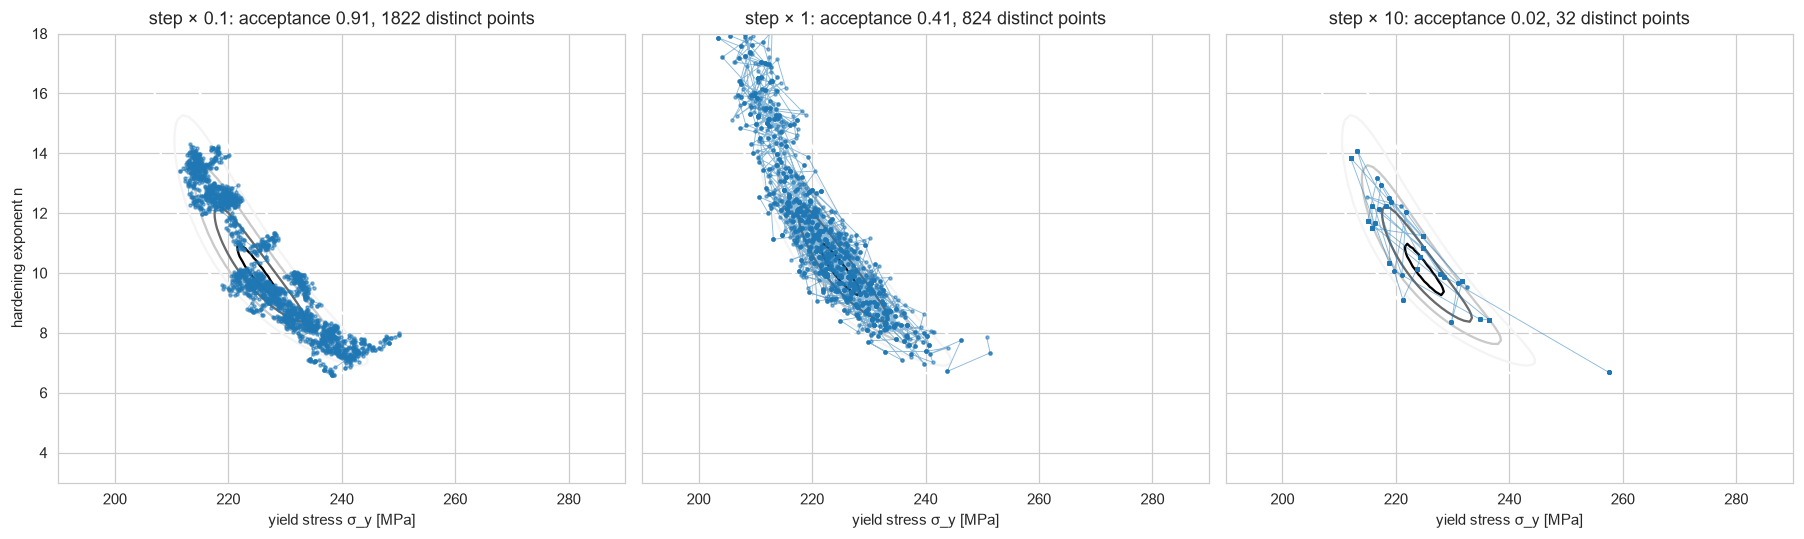

In [46]:
STEP_FACTORS = [0.1, 1.0, 10.0]   # multiples of MH_STEP

fig, axes = plt.subplots(1, len(STEP_FACTORS), figsize=(5.5 * len(STEP_FACTORS), 5), sharex=True, sharey=True)
for ax, factor in zip(axes, STEP_FACTORS):
    chain, acceptance = metropolis_hastings(log_posterior, start=[PRIOR_SY[0], PRIOR_N[0]],
                                            step_scale=[MH_STEP[0] * factor, MH_STEP[1] * factor], n_steps=2000, burn_in=0)
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ax.plot(chain[:, 0], chain[:, 1], "-o", ms=2, lw=0.6, color="C0", alpha=0.5)
    ax.set_title(f"step × {factor:g}: acceptance {acceptance:.2f}, {len(np.unique(chain, axis=0))} distinct points")
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 18)
axes[0].set_ylabel("hardening exponent n")
plt.tight_layout()
plt.show()

With small steps, almost every proposal is accepted, but each step moves the chain very little, so successive samples are almost the same. With large steps, most proposals land far outside the ridge and are rejected, so the chain stays at the same point for long stretches. A good step size lies in between, with an acceptance rate of roughly 0.2 to 0.5.

### Variational Inference

We choose a family of distributions $q(\theta)$, here two-dimensional Gaussians $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ with a full covariance matrix, and look for the member of the family that is closest to the posterior. We start from the log evidence and multiply and divide by $q$ inside the integral:

$$
\log p(\mathcal{D}) = \log \int p(\mathcal{D} \mid \theta)\, p(\theta)\, \frac{q(\theta)}{q(\theta)}\, d\theta
= \log \mathbb{E}_q\!\left[\frac{p(\mathcal{D} \mid \theta)\, p(\theta)}{q(\theta)}\right]
\ge \mathbb{E}_q\!\left[\log \frac{p(\mathcal{D} \mid \theta)\, p(\theta)}{q(\theta)}\right].
$$

The inequality is Jensen's inequality: since the log is concave, the log of an average is greater than or equal to the average of the log. The right-hand side is called the **evidence lower bound (ELBO)**. Splitting the log gives

$$
\text{ELBO}(q) = \mathbb{E}_q\left[\log p(\mathcal{D} \mid \theta)\right] - \mathrm{KL}\big(q(\theta)\,\|\,p(\theta)\big).
$$

The first term is large when $q$ puts its probability where the model fits the data well. The second term is small when $q$ is close to the prior. The difference between the two sides of the inequality is the KL divergence from $q$ to the posterior (the *reverse* KL, because $q$ comes first; see the chapter on distribution distances):

$$
\log p(\mathcal{D}) = \text{ELBO}(q) + \mathrm{KL}\big(q(\theta)\,\|\,p(\theta \mid \mathcal{D})\big).
$$

The left side does not depend on $q$. So maximizing the ELBO over $q$ is the same as minimizing this KL divergence, and we never need to compute the evidence.

To maximize the ELBO with gradient-based optimization, we write each draw from $q$ as $\theta = \boldsymbol{\mu} + \mathbf{L}\boldsymbol{\xi}$, with $\boldsymbol{\xi} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $\boldsymbol{\Sigma} = \mathbf{L}\mathbf{L}^\top$. This is the *reparameterization trick*: the randomness is in $\boldsymbol{\xi}$, so we can differentiate with respect to $\boldsymbol{\mu}$ and $\mathbf{L}$. We estimate the expectation with a Monte Carlo average over a few draws. In two dimensions the covariance matrix is

$$
\boldsymbol{\Sigma} = \begin{bmatrix} s_1^2 & \rho\, s_1 s_2 \\ \rho\, s_1 s_2 & s_2^2 \end{bmatrix},
$$

where $s_1, s_2$ are the standard deviations of $q$ and $\rho$ is their correlation. A diagonal $\boldsymbol{\Sigma}$ has $\rho = 0$. The code computes the ELBO in the equivalent form $\mathbb{E}_q[\log p(\mathcal{D} \mid \theta)\,p(\theta)] + H(q)$, where $H(q) = \log|\det \mathbf{L}| + 1 + \log 2\pi$ is the entropy of a two-dimensional Gaussian. Our `log_posterior` leaves out normalizing constants, so the ELBO values printed by the code differ from the true ELBO by a constant. This does not change which $q$ maximizes it. The result is the member of the chosen family that is closest to the posterior.

In [47]:
#| code-fold: false
def fit_gaussian_vi(log_target, init_mean, init_std, n_iterations=3000, n_draws=32, lr=0.05, seed=SEED):
    """Fit a 2D Gaussian q(theta) = N(mu, L L^T) to the target by maximizing the ELBO.

    The ELBO is E_q[log p(theta, data)] + entropy(q). The expectation is
    estimated from n_draws samples written as theta = mu + L * xi with
    xi ~ N(0, I), so gradients flow to mu and L through the samples.
    Returns the fitted mean, covariance, the ELBO history, and the mean and
    covariance of q at every iteration.
    """
    torch.manual_seed(seed)
    mu = torch.tensor(init_mean, dtype=torch.float64, requires_grad=True)
    L = torch.diag(torch.tensor(init_std, dtype=torch.float64)).clone().requires_grad_(True)
    optimizer = torch.optim.Adam([mu, L], lr=lr)
    history, path = [], []
    for _ in range(n_iterations):
        xi = torch.randn(n_draws, 2, dtype=torch.float64)
        L_lower = torch.tril(L)
        path.append((mu.detach().numpy().copy(), (L_lower @ L_lower.T).detach().numpy().copy()))
        theta = mu + xi @ L_lower.T
        entropy = torch.log(torch.abs(torch.diagonal(L_lower))).sum() + 1.0 + np.log(2 * np.pi)
        elbo = log_target(theta[:, 0], theta[:, 1]).mean() + entropy
        optimizer.zero_grad()
        (-elbo).backward()
        optimizer.step()
        history.append(float(elbo))
    L_lower = torch.tril(L).detach()
    return mu.detach().numpy(), (L_lower @ L_lower.T).numpy(), np.array(history), path


# Start narrow in n: a draw with n below zero makes the material law undefined (NaN)
vi_mean, vi_cov, vi_elbo, vi_path = fit_gaussian_vi(log_posterior, init_mean=[PRIOR_SY[0], PRIOR_N[0]], init_std=[30.0, 1.0])
vi_std = np.sqrt(np.diag(vi_cov))
print(f"VI:   sigma_y = {vi_mean[0]:.1f} ± {vi_std[0]:.1f} MPa,  n = {vi_mean[1]:.2f} ± {vi_std[1]:.2f},  "
      f"correlation {vi_cov[0, 1] / (vi_std[0] * vi_std[1]):.2f}")

VI:   sigma_y = 224.1 ± 6.2 MPa,  n = 10.61 ± 1.50,  correlation -0.86


### How VI fits its Gaussian proposal distribution

The figure below shows the Gaussian $q$ at five iterations of the optimization: its $2\sigma$ ellipse and 32 draws from it, the same number of draws used to estimate the ELBO at each iteration. The bottom panel shows the ELBO estimate at every iteration.

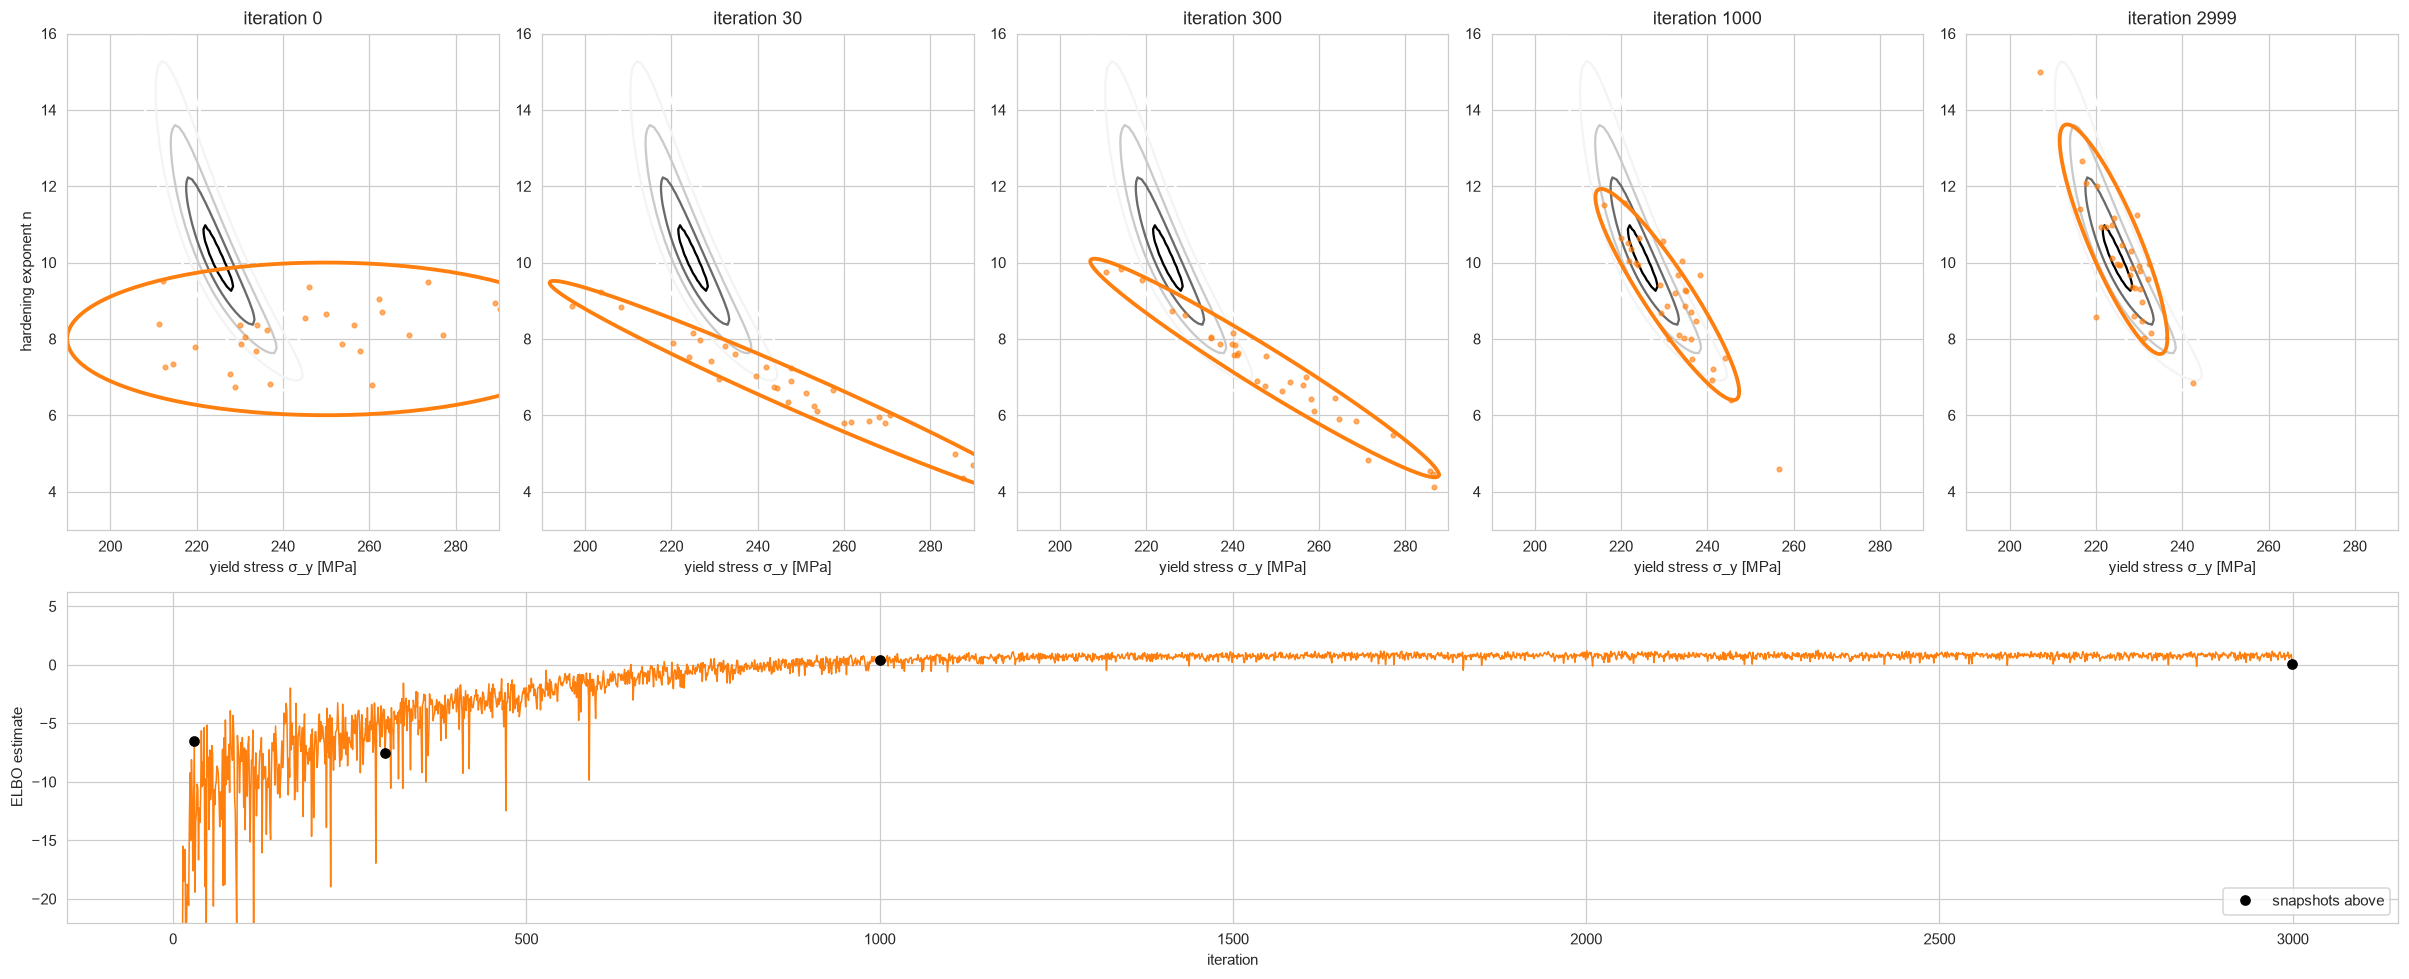

In [48]:
def gaussian_ellipse(mean, cov, n_std=2.0, n_points=200):
    """Boundary of the n_std-sigma ellipse of a 2D Gaussian."""
    angles = np.linspace(0, 2 * np.pi, n_points)
    circle = np.stack([np.cos(angles), np.sin(angles)])
    L = np.linalg.cholesky(cov)
    pts = np.asarray(mean)[:, None] + n_std * L @ circle
    return pts[0], pts[1]


VI_SNAPSHOTS = [0, 30, 300, 1000, 2999]   # iterations to show

fig = plt.figure(figsize=(22, 9))
grid_spec = fig.add_gridspec(2, len(VI_SNAPSHOTS), height_ratios=[1.2, 0.8])
draw_rng = np.random.default_rng(SEED)
for k, it in enumerate(VI_SNAPSHOTS):
    ax = fig.add_subplot(grid_spec[0, k])
    mean, cov = vi_path[it]
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ex, ey = gaussian_ellipse(mean, cov)
    ax.plot(ex, ey, color="C1", lw=2.5)
    draws = draw_rng.multivariate_normal(mean, cov, size=32)
    ax.plot(draws[:, 0], draws[:, 1], ".", color="C1", alpha=0.6)
    ax.set_title(f"iteration {it}")
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 16)
    if k == 0:
        ax.set_ylabel("hardening exponent n")
ax = fig.add_subplot(grid_spec[1, :])
ax.plot(vi_elbo, color="C1", lw=1)
ax.plot(VI_SNAPSHOTS, vi_elbo[VI_SNAPSHOTS], "ko", label="snapshots above")
ax.set_ylim(np.percentile(vi_elbo, 1) - 5, vi_elbo.max() + 5)
ax.set_xlabel("iteration")
ax.set_ylabel("ELBO estimate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

At the start, $q$ is the wide, untilted Gaussian we initialized, and most of its draws fall where the posterior is tiny. After about 30 iterations it is tilted. It then shrinks and moves along the ridge toward the peak. By iteration 1000 it is close to the peak, and it changes little after that. The ELBO increases quickly at first and then levels off. The noise in the ELBO curve comes from estimating it with only 32 draws per iteration.

The slider below steps through every stored iteration of the same optimization. The left panel shows $q$ at that iteration with 32 draws from it. The right panel marks the iteration on the ELBO curve.

In [ ]:
def show_vi_iteration(iteration=0):
    # The stored VI path vi_path at one iteration, and the ELBO curve
    mean, cov = vi_path[iteration]
    draws = np.random.default_rng(iteration).multivariate_normal(mean, cov, size=32)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
    ax = axes[0]
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ex, ey = gaussian_ellipse(mean, cov)
    ax.plot(ex, ey, color="C1", lw=2.5)
    ax.plot(draws[:, 0], draws[:, 1], ".", color="C1", alpha=0.7)
    ax.plot(mean[0], mean[1], "o", color="C3", ms=7)
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 16)
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_ylabel("hardening exponent n")
    std = np.sqrt(np.diag(cov))
    ax.set_title(f"iteration {iteration}: mean ({mean[0]:.0f} MPa, {mean[1]:.1f}), std ({std[0]:.1f} MPa, {std[1]:.2f})")

    ax = axes[1]
    ax.plot(vi_elbo, color="C1", lw=0.8, alpha=0.5)
    ax.plot(iteration, vi_elbo[iteration], "o", color="C3", ms=8)
    ax.set_ylim(np.percentile(vi_elbo, 1) - 5, vi_elbo.max() + 5)
    ax.set_xlabel("iteration")
    ax.set_ylabel("ELBO estimate")
    ax.set_title("ELBO")
    plt.tight_layout()
    plt.show()


vi_slider = widgets.IntSlider(value=0, min=0, max=len(vi_path) - 1, step=1, description="iteration", continuous_update=True,
                              layout=widgets.Layout(width="500px"))
vi_play = widgets.Play(value=0, min=0, max=len(vi_path) - 1, step=10, interval=100, description="play")
widgets.jslink((vi_play, "value"), (vi_slider, "value"))
display(widgets.HBox([vi_play, vi_slider]))
widgets.interactive_output(show_vi_iteration, {"iteration": vi_slider})

Output()

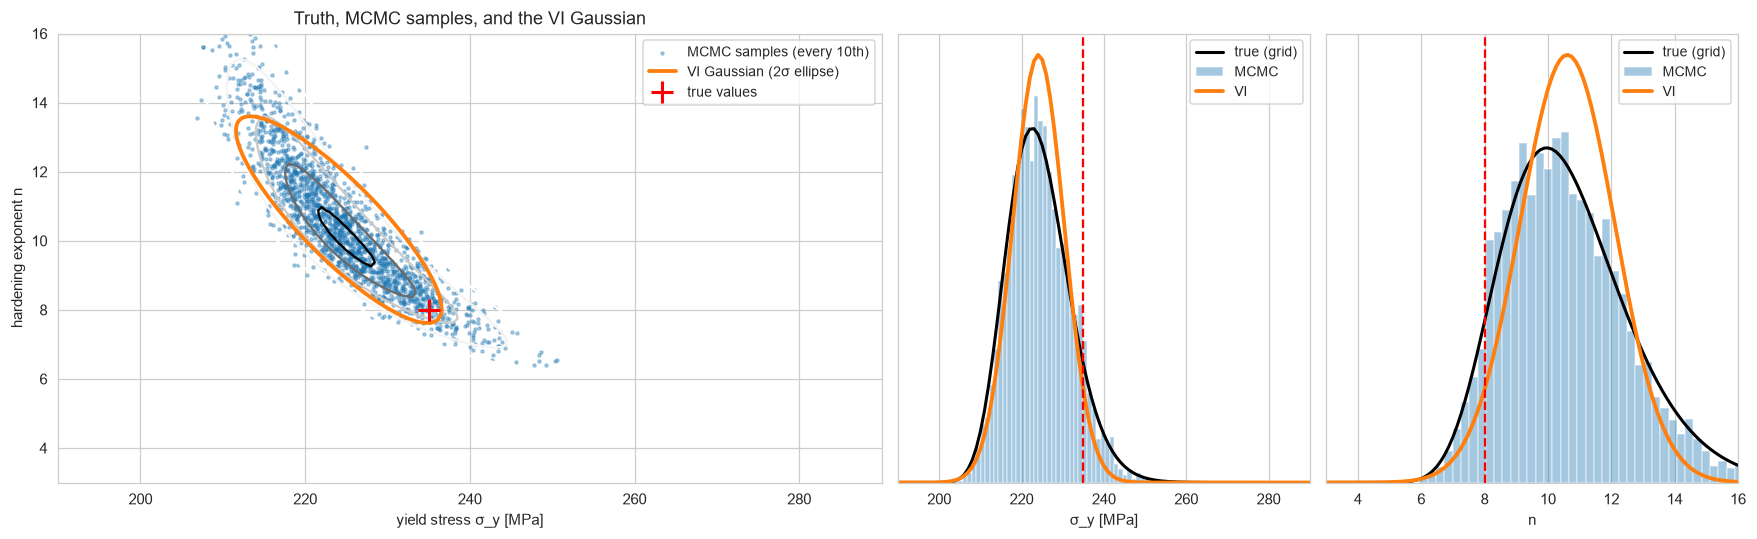

In [50]:
def plot_three_ways(mh_samples, vi_mean, vi_cov, posterior_grid, title="Truth, MCMC samples, and the VI Gaussian"):
    """The one picture: grid truth as contours, MCMC as points, VI as an ellipse, with marginals."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1, 1]})
    ax = axes[0]
    ax.contour(SY, NN, posterior_grid, levels=contour_levels(posterior_grid), cmap="Greys")
    ax.scatter(mh_samples[::10, 0], mh_samples[::10, 1], s=4, alpha=0.35, color="C0", label="MCMC samples (every 10th)")
    ex, ey = gaussian_ellipse(vi_mean, vi_cov)
    ax.plot(ex, ey, color="C1", lw=2.5, label="VI Gaussian (2σ ellipse)")
    ax.plot(SIGMA_Y_TRUE, N_TRUE, "r+", ms=14, mew=2, label="true values")
    ax.set_xlim(190, 290)
    ax.set_ylim(3, 16)
    ax.set_xlabel("yield stress σ_y [MPa]")
    ax.set_ylabel("hardening exponent n")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=9)

    # Marginals: grid (exact), MCMC histogram, VI Gaussian
    for ax, k, grid_axis, label, true_val in [
        (axes[1], 0, sy_grid, "σ_y [MPa]", SIGMA_Y_TRUE),
        (axes[2], 1, n_grid, "n", N_TRUE),
    ]:
        marginal = posterior_grid.sum(axis=1 - k)
        spacing = grid_axis[1] - grid_axis[0]
        ax.plot(grid_axis, marginal / spacing, color="k", lw=2, label="true (grid)")
        ax.hist(mh_samples[:, k], bins=50, density=True, alpha=0.4, color="C0", label="MCMC")
        x = grid_axis
        m, s = vi_mean[k], np.sqrt(vi_cov[k, k])
        ax.plot(x, np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi)), color="C1", lw=2.5, label="VI")
        ax.axvline(true_val, color="r", ls="--")
        ax.set_xlabel(label)
        ax.set_yticks([])
        ax.legend(fontsize=9)
    axes[1].set_xlim(190, 290)
    axes[2].set_xlim(3, 16)
    plt.tight_layout()
    return fig


plot_three_ways(mh_samples, vi_mean, vi_cov, posterior_grid)
plt.show()

In the left panel, the MCMC samples follow the grey ridge, including its curvature. The VI ellipse has the right center and tilt, because a full-covariance Gaussian can represent a correlation. But a Gaussian cannot be curved, so the ellipse stays inside the ridge and misses both ends. As a result, the VI marginals (orange) on the right are narrower and more symmetric than the true marginals (black). Here VI underestimates the uncertainty. In a certification setting, underestimating the uncertainty is the more dangerous error.

On this problem both methods take a few seconds. The difference appears as the number of parameters grows. A random-walk sampler must take smaller steps in higher dimensions, so it needs many more steps to cover the posterior. VI is an optimization that uses gradients, the same tool used to train neural networks, and it can handle millions of parameters.

::: {.callout-tip appearance="default"}
### Experiment: Step size, burn-in and iterations
To help build your understanding, you can try to following experiments with the above code:

- Predict the acceptance rate and the look of the chain for step factors 0.3 and 3. Add them to `STEP_FACTORS` and re-run that cell. Which step size would you choose, and why?
- Use the chain slider to find the step at which the chain first reaches the ridge. Is a burn-in of 2000 steps more than we need? What would go wrong with no burn-in at all?
- Use the VI slider to see where the Gaussian sits after 300 iterations. What would the chapter's answer look like if we had stopped the optimization there?
:::

## What Each Method Gives You

| | MCMC (sampling) | VI (optimization) |
|---|---|---|
| Output | A set of samples from the posterior | The parameters of the closest distribution in a chosen family |
| What can go wrong | With too few or badly tuned steps, the samples do not yet represent the posterior; this is hard to detect from the samples alone | The family cannot represent the posterior (a Gaussian cannot be curved), so the result is biased, usually too narrow |
| Cost | Many evaluations of the model; the number grows quickly with the number of parameters | A fixed optimization budget; works for very large models |
| When to use it | Small to medium models where accuracy matters more than speed; as a reference to check other methods | Large models, repeated inference, inference inside a training loop |

VI tends to underestimate the uncertainty. Maximizing the ELBO penalizes $q$ for putting probability where the posterior is small, so the Gaussian shrinks to fit inside the ridge instead of covering it. This is the mode-seeking behavior of the reverse KL divergence from the chapter on distribution distances. VI appears again in Part 2, where variational autoencoders use it to train a generative model.

## From Parameters to Predictions

We are not interested in $(\sigma_y, n)$ for their own sake. We want to predict the stress at strains we did not test, with reliable error bars. Each method gives a set of plausible parameter pairs. We evaluate the material law for each pair and collect the resulting curves. The spread of these curves at a given strain is the predictive uncertainty at that strain.

We do this three times: with samples drawn from the grid posterior, with the MCMC samples, and with draws from the VI Gaussian. The strain axis extends past the last load step to show how each method extrapolates.

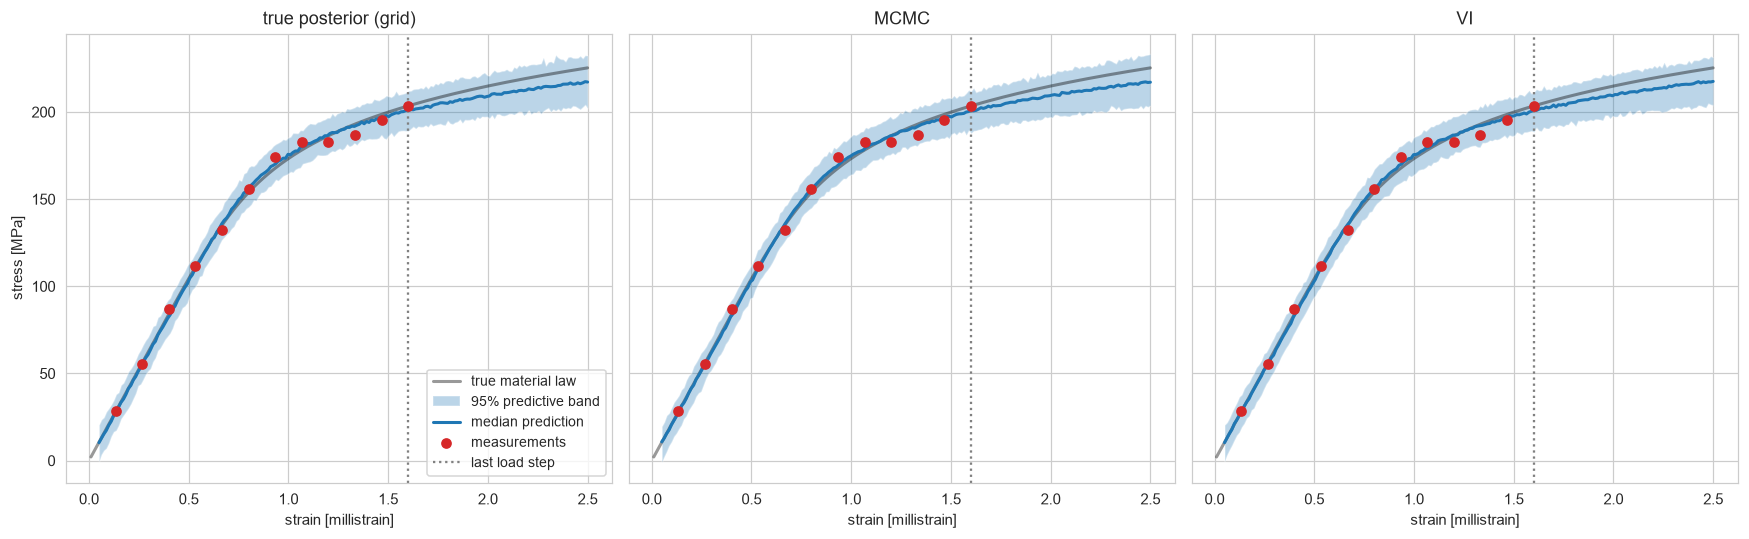

true posterior (grid)  stress at 2.5 millistrain: 217 MPa, 95% band width 28 MPa
MCMC                   stress at 2.5 millistrain: 217 MPa, 95% band width 30 MPa
VI                     stress at 2.5 millistrain: 217 MPa, 95% band width 28 MPa


In [51]:
def predictive_band(param_samples, strain_new, noise_std=NOISE_STD, rng=rng):
    """2.5, 50 and 97.5 percent quantiles of predicted stress at strain_new, including measurement noise."""
    params = np.asarray(param_samples)
    stress = ramberg_osgood_stress(strain_new[None, :], params[:, 0:1], params[:, 1:2], E=E_FIXED)
    stress = stress + rng.normal(0.0, noise_std, size=stress.shape)
    return np.percentile(stress, [2.5, 50, 97.5], axis=0)


def sample_from_grid(n_samples=400, rng=rng):
    """Draw parameter pairs from the grid posterior (the ground truth)."""
    flat = posterior_grid.ravel()
    idx = rng.choice(flat.size, size=n_samples, p=flat / flat.sum())
    return np.stack([SY.ravel()[idx], NN.ravel()[idx]], axis=1)


strain_new = np.linspace(0.05e-3, 2.5e-3, 200)
bands = {
    "true posterior (grid)": predictive_band(sample_from_grid(400), strain_new),
    "MCMC": predictive_band(mh_samples[::45], strain_new),
    "VI": predictive_band(np.random.default_rng(SEED).multivariate_normal(vi_mean, vi_cov, size=400), strain_new),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (name, (lo, mid, hi)) in zip(axes, bands.items()):
    ax.plot(strain_fine * 1e3, stress_true_curve, "k-", lw=2, alpha=0.4, label="true material law")
    ax.fill_between(strain_new * 1e3, lo, hi, alpha=0.3, label="95% predictive band")
    ax.plot(strain_new * 1e3, mid, lw=2, label="median prediction")
    ax.scatter(strain_obs * 1e3, stress_obs, color="C3", zorder=5, label="measurements")
    ax.axvline(strain_obs.max() * 1e3, color="gray", ls=":", label="last load step")
    ax.set_title(name)
    ax.set_xlabel("strain [millistrain]")
axes[0].set_ylabel("stress [MPa]")
axes[0].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

for name, (lo, mid, hi) in bands.items():
    i = np.searchsorted(strain_new, 2.5e-3) - 1
    print(f"{name:22s} stress at 2.5 millistrain: {mid[i]:.0f} MPa, 95% band width {hi[i] - lo[i]:.0f} MPa")

Inside the tested range, all three bands agree and follow the data. Beyond the last load step they all widen, because there the correlated uncertainty in yield stress and hardening exponent matters more. Here the three bands have almost the same width (compare the printed widths), even though the VI Gaussian is too narrow in $n$. Along the ridge, a higher yield stress comes with a lower hardening exponent, and these pairs give similar stresses up to 2.5 millistrain. So the parts of the posterior that VI misses give curves close to the others. This is not always the case. If the missed parts of the posterior correspond to physically different behavior, the VI band can be much too narrow, and the VI result alone gives no sign of it. So for expensive decisions, it is worth checking a VI result against MCMC, which is slower but samples the actual posterior.

## Summary and Next Steps

- A posterior distribution answers questions that a point estimate cannot: how uncertain the parameters are, where the model is reliable, and how much more data would help.
- **MLE** maximizes the likelihood, **MAP** adds the log prior, and the **posterior** keeps the whole distribution. Ridge regression is MAP with a Gaussian prior on the weights.
- With a Gaussian prior and Gaussian noise, any model that is **linear in its parameters** has an exact Gaussian posterior and an exact posterior predictive, whether the features are straight lines or polynomials.
- When parameters enter **nonlinearly**, as in a real material law, the posterior has no closed form. We can evaluate it at any point, but we can only integrate it by brute force when there are one or two parameters.
- Integrals over the posterior can be replaced by **Monte Carlo** averages over samples. Importance sampling with the prior as proposal wastes most of its samples.
- **MCMC** (here Metropolis-Hastings) draws samples from the posterior using only the unnormalized posterior, because the evidence cancels in the acceptance ratio. It is accurate if run long enough, but expensive, and convergence is hard to check.
- **VI** maximizes the ELBO, a lower bound on the log evidence, which is the same as minimizing the reverse KL divergence to the posterior. It returns the member of a chosen family that is closest to the posterior. It is fast and scales to large models, but it underestimates the uncertainty when the family cannot match the shape of the posterior.
- Predictive uncertainty is what you use in a design. Compute it by passing parameter samples through the physical model, and keep in mind that VI bands are too narrow when the VI posterior is.

**Where to go next.**

*Advanced Approximate Inference: MCMC and Variational Inference* covers both methods in more detail: why plain Monte Carlo fails, how Metropolis-Hastings and Hamiltonian Monte Carlo work and how to tune them, where the ELBO comes from, and how both scale to the weights of a neural network. That chapter is optional.

*Introduction to Probabilistic Programming* solves the same problem as this chapter, the S235 tensile test, with a probabilistic programming language that provides the sampler and the variational fit, so that you only need to write the model.